   Unnamed: 0      key  fare_amount          pickup_datetime  \
0    24238194  52:06.0          7.5  2015-05-07 19:52:06 UTC   
1    27835199  04:56.0          7.7  2009-07-17 20:04:56 UTC   
2    44984355  45:00.0         12.9  2009-08-24 21:45:00 UTC   
3    25894730  22:21.0          5.3  2009-06-26 08:22:21 UTC   
4    17610152  47:00.0         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1  
2                1  
3                3  
4                5  


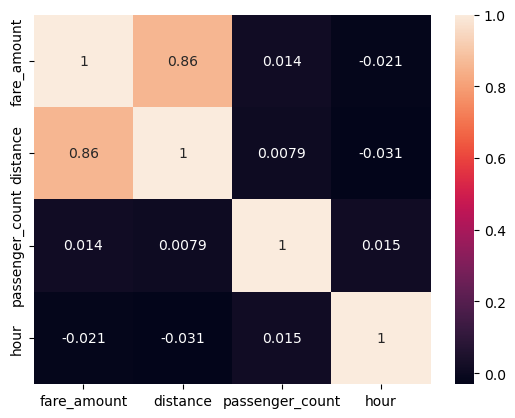

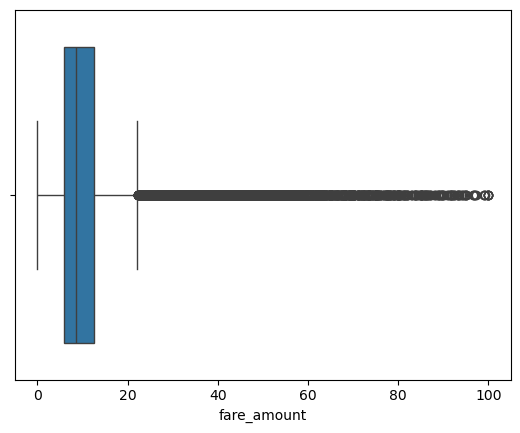

LINEAR REGRESSION
R2 Score: 0.7282884385303032
RMSE: 4.926239363739804

RANDOM FOREST
R2 Score: 0.7658700895318896
RMSE: 4.572881007249993


In [1]:
# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error


# 2. Load dataset

df = pd.read_csv("uber.csv")

print(df.head())


# 3. Preprocess data

df = df.drop(['Unnamed: 0', 'key'], axis=1)

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce'
)

df = df.dropna()

df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 100)]

df = df[df['passenger_count'].between(1, 6)]


# 4. Calculate distance using Haversine

lat1 = np.radians(df['pickup_latitude'])
lon1 = np.radians(df['pickup_longitude'])

lat2 = np.radians(df['dropoff_latitude'])
lon2 = np.radians(df['dropoff_longitude'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2

df['distance'] = 6371 * 2 * np.arcsin(np.sqrt(a))


# 5. Extract pickup hour

df['hour'] = df['pickup_datetime'].dt.hour


# 6. Remove invalid locations and distances

df = df[
    (df['pickup_latitude'].between(40, 42)) &
    (df['dropoff_latitude'].between(40, 42)) &
    (df['pickup_longitude'].between(-75, -72)) &
    (df['dropoff_longitude'].between(-75, -72)) &
    (df['distance'] > 0) &
    (df['distance'] <= 100)
]


# 7. Check correlation and outliers

sns.heatmap(
    df[['fare_amount', 'distance', 'passenger_count', 'hour']].corr(),
    annot=True
)
plt.show()

sns.boxplot(x=df['fare_amount'])
plt.show()


# 8. Select input and output

X = df[['distance', 'passenger_count', 'hour']]

y = df['fare_amount']


# 9. Split data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# 10. Linear Regression

lr = LinearRegression()

lr.fit(X_train, y_train)

pred1 = lr.predict(X_test)


# 11. Random Forest Regression

rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)

rf.fit(X_train, y_train)

pred2 = rf.predict(X_test)


# 12. Evaluate models

print("LINEAR REGRESSION")
print("R2 Score:", r2_score(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))


print("\nRANDOM FOREST")
print("R2 Score:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))